<a href="https://colab.research.google.com/github/thegarbzinvasion/abalone-data-imbalance-comparison/blob/main/abalone_data_imbalance_comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##1.Importing & Extracting Dataset

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import zipfile

zip_path = '/content/drive/MyDrive/Tutorial3data/abalone.zip'
with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall('Abalone Data Imblance Handling')

##2. Data Exploration

In [3]:
import pandas as pd

column_names = [
    'Sex',
    'Length',
    'Diameter',
    'Height',
    'Whole weight',
    'Shucked weight',
    'Viscera weight',
    'Shell weight',
    'Rings'
]

df = pd.read_csv('/content/Abalone Data Imblance Handling/abalone.data', names=column_names)

df.head()

,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4177 entries, 0 to 4176
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Sex             4177 non-null   object 
 1   Length          4177 non-null   float64
 2   Diameter        4177 non-null   float64
 3   Height          4177 non-null   float64
 4   Whole weight    4177 non-null   float64
 5   Shucked weight  4177 non-null   float64
 6   Viscera weight  4177 non-null   float64
 7   Shell weight    4177 non-null   float64
 8   Rings           4177 non-null   int64  
dtypes: float64(7), int64(1), object(1)
memory usage: 293.8+ KB


In [5]:
df.describe()

,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
count,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000
mean,0.523992,0.407881,0.139516,0.828742,0.359367,0.180594,0.238831,9.933684
std,0.120093,0.099240,0.041827,0.490389,0.221963,0.109614,0.139203,3.224169
min,0.075000,0.055000,0.000000,0.002000,0.001000,0.000500,0.001500,1.000000
25%,0.450000,0.350000,0.115000,0.441500,0.186000,0.093500,0.130000,8.000000
50%,0.545000,0.425000,0.140000,0.799500,0.336000,0.171000,0.234000,9.000000
75%,0.615000,0.480000,0.165000,1.153000,0.502000,0.253000,0.329000,11.000000
max,0.815000,0.650000,1.130000,2.825500,1.488000,0.760000,1.005000,29.000000


In [6]:
print(f'Rows and Columns of Dataset: {df.shape}')

Rows and Columns of Dataset: (4177, 9)


###2.1. Checking for Imbalance (Target Variable "Rings", Multi-class Obj "Sex")

In [7]:
print(df['Sex'].value_counts())
print(df['Rings'].value_counts().sort_index())

Sex
M    1528
I    1342
F    1307
Name: count, dtype: int64
Rings
1       1
2       1
3      15
4      57
5     115
6     259
7     391
8     568
9     689
10    634
11    487
12    267
13    203
14    126
15    103
16     67
17     58
18     42
19     32
20     26
21     14
22      6
23      9
24      2
25      1
26      1
27      2
29      1
Name: count, dtype: int64


####2.1.1. Checking for Outliers and Imbalance in Continous Data Columns

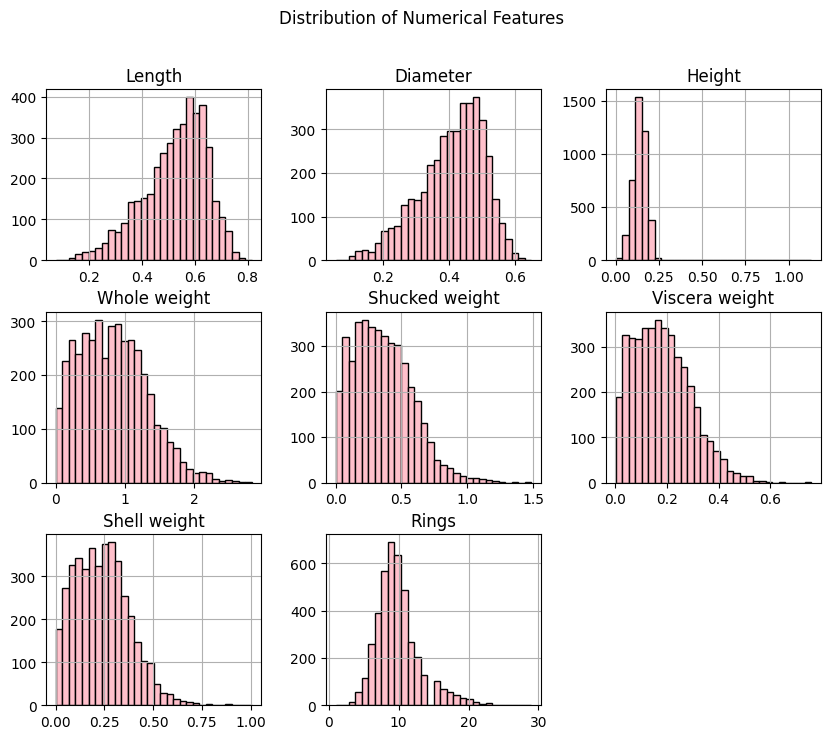

In [21]:
import matplotlib.pyplot as plt

df.hist(bins=30, figsize=(10,8), color='pink', edgecolor='black')
plt.suptitle('Distribution of Numerical Features')
plt.show()

##3. Classification Model Training (Without Sampling Techniques)

In [9]:
def group_rings_to_age(rings):
    if rings < 8:
        return 'Baby'
    elif rings < 11:
        return 'Teenager'
    else:
        return 'Old'

df['Age_Group'] = df['Rings'].apply(group_rings_to_age);
print(df['Age_Group'].value_counts());

Age_Group
Teenager    1891
Old         1447
Baby         839
Name: count, dtype: int64


In [10]:
from sklearn.model_selection import train_test_split

df_encoded = pd.get_dummies(df, columns=['Sex'] , drop_first=True)

X = df_encoded.drop(['Rings', 'Age_Group'], axis=1)
y = df_encoded['Age_Group']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

rf_classifier = RandomForestClassifier(random_state=42)
rf_classifier.fit(X_train, y_train)

y_pred = rf_classifier.predict(X_test)

print("Classification Report:\n", classification_report(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

Classification Report:
               precision    recall  f1-score   support

        Baby       0.81      0.70      0.75       180
         Old       0.64      0.69      0.67       276
    Teenager       0.65      0.66      0.66       380

    accuracy                           0.68       836
   macro avg       0.70      0.68      0.69       836
weighted avg       0.68      0.68      0.68       836


Confusion Matrix:
 [[126   2  52]
 [  5 190  81]
 [ 25 103 252]]


##4. Handling Class Imbalance (RandomOverSampler)

In [12]:
from imblearn.over_sampling import RandomOverSampler

print('Before oversampling: ')
print(y_train.value_counts())

ros = RandomOverSampler(random_state=42)
X_train_resampled, y_train_resampled = ros.fit_resample(X_train, y_train)

print('\nAfter oversampling: ')
print(y_train_resampled.value_counts())

Before oversampling: 
Age_Group
Teenager    1511
Old         1171
Baby         659
Name: count, dtype: int64

After oversampling: 
Age_Group
Old         1511
Teenager    1511
Baby        1511
Name: count, dtype: int64


###4.1. Training Random Forest Classification model using Resampled Training Set

In [13]:
balanced_classifier = RandomForestClassifier(random_state=42)
balanced_classifier.fit(X_train_resampled, y_train_resampled)

y_pred_over = balanced_classifier.predict(X_test)

print("Classification Report:\n", classification_report(y_test, y_pred_over))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_over))

Classification Report:
               precision    recall  f1-score   support

        Baby       0.77      0.75      0.76       180
         Old       0.64      0.72      0.67       276
    Teenager       0.68      0.62      0.65       380

    accuracy                           0.68       836
   macro avg       0.70      0.70      0.69       836
weighted avg       0.68      0.68      0.68       836


Confusion Matrix:
 [[135   3  42]
 [  7 198  71]
 [ 33 110 237]]


##5. Results

After handling the class imbalance problem with RandomOverSampler, an oversampling technique, the recall was boosted for the minority age group classes (Baby and Old), as there was more rows of data, the model was to pay more attention to them during training.

However, with random oversampling, the boundaries to differentiate between classes become unclear due to the duplication of rows, so the accuracy on the largest class, Teenager, went down a bit.